# Part 4 of 4: Diagnostics, forecast, challenges and reflection
**Project:** How High Will Gas Prices Get Tomorrow? · **Team:** Orville Rockwell Jr., Yi-Ting Lin, Wejun Chen, Yixin Tian

**Owner:** Yixin Tian

Calibration, error analysis, contract scoring and backtest, tomorrow's forecast, then the written challenges and reflection.

**Your task:** improve this part in 5 specific ways. Put each in a Markdown cell titled **Revision** (what you changed, why, and the result), and keep a log of what you did and when for the contribution table.

## Setup (run this cell first, every time)
It installs any missing packages, then writes the project code (`gaslab/`) and the real data (`data/`) into this
notebook's folder **only if they are not there yet**. If you edit a file in `gaslab/` or drop newer CSVs in `data/`,
re-running this cell will not overwrite them. Data: EIA/FRED weekly retail and daily wholesale and crude prices
from Jan 2014 to Oct 2026, plus every settled Kalshi AAA gas contract (the daily AAA labels).

In [1]:
import sys, os, base64, shutil, subprocess, importlib.util
need = [pkg for pkg, mod in [("arch", "arch"), ("statsmodels", "statsmodels"), ("scikit-learn", "sklearn"),
                             ("tensorflow", "tensorflow"), ("matplotlib", "matplotlib"), ("scipy", "scipy")]
        if importlib.util.find_spec(mod) is None]
if need:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need]); print("installed:", need)
VERSION = '2026-10-20'
CODE = {'__init__.py': '', 'data.py': '"""Data layer: FRED wholesale/crude/retail + Kalshi AAA settlements -> leak-free feature tensors.\n\nTiming conventions (all decisions are made with information available at the bid time):\n  * Weekly model: origin = Monday t (EIA retail R_t surveyed 8 a.m. Monday). Target = log(R_{t+1}/R_t).\n    Wholesale/crude inputs use closes through the Friday before Monday t.\n  * Daily model: origin = 8:00 a.m. ET on day D-1, when Kalshi opens the contract settling on day D.\n    AAA\'s D-1 average is already posted (Kalshi centres the strike ladder on it). Wholesale/crude\n    inputs use closes through business day D-2. Target = log(A_D/A_{D-1}).\n"""\nfrom pathlib import Path\nimport numpy as np, pandas as pd\n\nDATA = Path(__file__).resolve().parent.parent / "data"\nGAL_PER_BBL = 42.0\n\n\ndef load_fred():\n    f = pd.read_csv(DATA / "fred.csv", parse_dates=["date"]).set_index("date").sort_index()\n    f["wti"] /= GAL_PER_BBL; f["brent"] /= GAL_PER_BBL            # $/bbl -> $/gal\n    f.loc[f["wti"] <= 0, "wti"] = np.nan                           # 2020-04-20 negative WTI print\n    return f\n\n\ndef load_aaa_daily():\n    """AAA national regular average by date, from Kalshi settlement values plus any manual rows."""\n    k = pd.read_csv(DATA / "kalshi_markets.csv")\n    k = k[k.series.isin(["KXAAAGASD", "KXAAAGASW", "KXAAAGASM"])].copy()\n    k["date"] = pd.to_datetime(k.exp, utc=True).dt.tz_convert("America/New_York").dt.normalize().dt.tz_localize(None)\n    k["value"] = pd.to_numeric(k.value, errors="coerce")\n    s = k.dropna(subset=["value"]).groupby("date").value.first()\n    manual = DATA / "manual_aaa.csv"                               # optional: date,aaa\n    if manual.exists():\n        m = pd.read_csv(manual, parse_dates=["date"]).set_index("date")["aaa"]\n        s = pd.concat([s, m]).groupby(level=0).last()\n    return s.sort_index().rename("aaa")\n\n\ndef daily_contracts(series="KXAAAGASD"):\n    k = pd.read_csv(DATA / "kalshi_markets.csv")\n    k = k[k.series == series].copy()\n    k["date"] = pd.to_datetime(k.exp, utc=True).dt.tz_convert("America/New_York").dt.normalize().dt.tz_localize(None)\n    k["y"] = (k.result == "yes").astype(float).where(k.result.isin(["yes", "no"]))\n    book = DATA / "kalshi_open_book.csv"\n    if book.exists():\n        k = k.merge(pd.read_csv(book)[["ticker", "bid", "ask", "hours_after_open"]], on="ticker", how="left")\n    return k\n\n\n# ----------------------------------------------------------------------------------- weekly (10 years)\nWEEKLY_FEATS = ["d_retail", "d_gulf", "d_nyh", "d_brent", "up_gulf", "dn_gulf", "ect", "garch_sd"]\n\n\ndef weekly_frame(f=None):\n    """One row per EIA Monday t with features known at t and target y = log(R_{t+1}/R_t)."""\n    f = load_fred() if f is None else f\n    r = f["retail_eia_weekly"].dropna()\n    bd = f[["whsl_gulf", "whsl_nyh", "brent"]].ffill()\n    rows = []\n    for t in r.index:\n        fri = bd.loc[: t - pd.Timedelta(days=3)].tail(5)            # Mon-Fri week ending the Friday before t\n        if len(fri) < 5: continue\n        rows.append(dict(date=t, retail=r.loc[t], gulf=fri.whsl_gulf.mean(), nyh=fri.whsl_nyh.mean(), brent=fri.brent.mean()))\n    w = pd.DataFrame(rows).set_index("date")\n    lw = np.log(w)\n    w["d_retail"] = lw.retail.diff(); w["d_gulf"] = lw.gulf.diff(); w["d_nyh"] = lw.nyh.diff(); w["d_brent"] = lw.brent.diff()\n    w["up_gulf"] = w.d_gulf.clip(lower=0); w["dn_gulf"] = w.d_gulf.clip(upper=0)         # rockets & feathers\n    spread = lw.retail - lw.gulf                                                          # retail margin (log)\n    w["ect"] = spread - spread.rolling(52, min_periods=26).mean()                        # error-correction term\n    w["y"] = w.d_retail.shift(-1)\n    return w\n\n\n# ----------------------------------------------------------------------------------- daily (Kalshi)\nDAILY_FEATS = ["d_aaa", "d_aaa_l2", "d_gulf", "d_brent", "ect", "w_drift", "garch_sd"]\n\n\ndef daily_frame(f=None, aaa=None, weekly_drift=None, extend_to=None):\n    """One row per settlement day D with features known at 8 a.m. ET on D-1.\n    extend_to adds future settlement dates (no target yet) so live contracts can be priced."""\n    f = load_fred() if f is None else f\n    aaa = load_aaa_daily() if aaa is None else aaa\n    a = aaa.asfreq("D")\n    if extend_to is not None and pd.Timestamp(extend_to) > a.index[-1]:\n        a = a.reindex(pd.date_range(a.index[0], extend_to, freq="D"))\n    bd = f[["whsl_gulf", "brent"]].ffill().asfreq("D").reindex(a.index.union(f.index)).ffill().reindex(a.index)\n    df = pd.DataFrame(index=a.index)\n    df["aaa_prev"] = a.shift(1)                                          # A_{D-1}\n    df["d_aaa"] = np.log(a).diff().shift(1)                              # change into D-1\n    df["d_aaa_l2"] = df["d_aaa"].shift(1)                                # change into D-2\n    g2 = np.log(bd.whsl_gulf).shift(2); b2 = np.log(bd.brent).shift(2)   # closes through D-2\n    df["d_gulf"] = g2.diff(); df["d_brent"] = b2.diff()\n    spread = np.log(df.aaa_prev) - g2.rolling(5).mean()\n    df["ect"] = spread - spread.rolling(28, min_periods=10).mean()\n    df["w_drift"] = 0.0 if weekly_drift is None else weekly_drift.reindex(df.index, method="ffill").fillna(0) / 7.0\n    df["y"] = np.log(a).diff()\n    return df\n\n\ndef sequences(df, feats, lookback, rows=None, allow_missing_y=()):\n    """Stack rolling windows of features ending at each row. Returns X, y, index.\n    Rows listed in allow_missing_y are kept even without a target (used for live forecasts)."""\n    vals = df[feats].values.astype("float32"); ys = df["y"].values.astype("float32")\n    idx = []; X = []; Y = []\n    want = set(df.index if rows is None else rows)\n    for i in range(lookback - 1, len(df)):\n        if df.index[i] not in want: continue\n        win = vals[i - lookback + 1: i + 1]\n        if np.isnan(win).any() or (np.isnan(ys[i]) and df.index[i] not in allow_missing_y): continue\n        X.append(win); Y.append(ys[i]); idx.append(df.index[i])\n    return np.array(X), np.array(Y), pd.DatetimeIndex(idx)\n', 'evaluate.py': '"""Scoring: distribution metrics, Kalshi strike-ladder pricing, accuracy variants, and a fee-aware backtest."""\nimport numpy as np, pandas as pd\nfrom scipy import stats\n\n\ndef cdf(x, mu, scale, df):\n    z = (x - mu) / scale\n    return np.where(np.isinf(df), stats.norm.cdf(z), stats.t.cdf(z, np.where(np.isinf(df), 30, df)))\n\n\ndef logpdf(y, mu, scale, df):\n    z = (y - mu) / scale\n    return np.where(np.isinf(df), stats.norm.logpdf(z), stats.t.logpdf(z, np.where(np.isinf(df), 30, df))) - np.log(scale)\n\n\ndef crps_mc(y, mu, scale, df, n=2000, seed=0):\n    rng = np.random.default_rng(seed); z = rng.standard_normal((n, len(y)))\n    t = np.where(np.isinf(df), z, rng.standard_t(np.where(np.isinf(df), 30, df), size=(n, len(y))))\n    s = mu + scale * t; s2 = mu + scale * np.roll(t, 1, axis=0)\n    return np.mean(np.abs(s - y), 0) - 0.5 * np.mean(np.abs(s - s2), 0)\n\n\ndef dist_metrics(y_pct, d):\n    mu, sc, nu = d.mu.values, d.scale.values, d.df.values\n    nz = y_pct != 0\n    return {"NLL": float(-logpdf(y_pct, mu, sc, nu).mean()),\n            "CRPS": float(crps_mc(y_pct, mu, sc, nu).mean()),\n            "MAE": float(np.abs(y_pct - mu).mean()),\n            "dir_acc": float((np.sign(mu[nz]) == np.sign(y_pct[nz])).mean()) if np.any(mu != 0) else np.nan,\n            "cov80": float(np.mean(np.abs(cdf(y_pct, mu, sc, nu) - 0.5) <= 0.4)),\n            "n": int(len(y_pct))}\n\n\ndef price_ladder(contracts, dist, prev_col="prev", extra_sd_pct=None):\n    """P(YES) = P(level_D > k) = 1 - F(100*ln(k/prev)). extra_sd_pct widens the scale (e.g. basis noise)."""\n    c = contracts.join(dist, on="date", how="inner")\n    sc = c.scale if extra_sd_pct is None else np.sqrt(c.scale ** 2 + extra_sd_pct ** 2)\n    x = 100 * np.log(c.strike / c[prev_col])\n    c["p"] = np.clip(1 - cdf(x, c.mu, sc, c.df), 1e-4, 1 - 1e-4)\n    return c\n\n\ndef contract_metrics(c, atm_cents=1.0):\n    y, p = c.y.values, c.p.values\n    atm = (np.abs(c.strike - c.prev) * 100 <= atm_cents).values\n    out = {"contracts": int(len(c)), "events": int(c.date.nunique()),\n           "accuracy": float(((p > 0.5) == (y == 1)).mean()),\n           "atm_accuracy": float(((p[atm] > 0.5) == (y[atm] == 1)).mean()) if atm.any() else np.nan,\n           "atm_n": int(atm.sum()),\n           "brier": float(np.mean((p - y) ** 2)),\n           "logloss": float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))}\n    return out\n\n\ndef kalshi_fee(price, rate=0.07):\n    """Kalshi taker fee per contract: rate * P * (1-P), rounded up to the centicent ($0.0001), per the Kalshi fee\n    schedule effective July 7, 2026. Resting (maker) orders on KXAAAGASD are not in the non-standard fee table,\n    so their maker multiplier defaults to 0 (no maker fee); this backtest conservatively assumes taker orders."""\n    return np.ceil(rate * price * (1 - price) * 10000 - 1e-9) / 10000\n\n\ndef backtest(c, edge=0.03):\n    """Take one contract per signal at the first-hour book after open. YES at ask, NO at (1-bid)."""\n    c = c.dropna(subset=["bid", "ask", "y"]).copy()\n    c = c[(c.ask > 0) & (c.ask < 1) & (c.bid > 0)]\n    buy_yes = c.p - c.ask - kalshi_fee(c.ask) > edge\n    no_px = 1 - c.bid\n    buy_no = (1 - c.p) - no_px - kalshi_fee(no_px) > edge\n    pnl = np.where(buy_yes, c.y - c.ask - kalshi_fee(c.ask), 0.0) + np.where(buy_no, (1 - c.y) - no_px - kalshi_fee(no_px), 0.0)\n    trades = buy_yes | buy_no\n    c["pnl"] = pnl; c["trade"] = trades\n    cost = np.where(buy_yes, c.ask, 0) + np.where(buy_no, no_px, 0)\n    return {"trades": int(trades.sum()), "hit_rate": float((pnl[trades] > 0).mean()) if trades.any() else np.nan,\n            "pnl_per_contract": float(pnl[trades].mean()) if trades.any() else np.nan,\n            "total_pnl_$": float(pnl.sum()), "capital_$": float(cost.sum()),\n            "roi": float(pnl.sum() / cost.sum()) if cost.sum() else np.nan}, c\n\n\ndef market_metrics(c):\n    m = c.dropna(subset=["bid", "ask", "y"]).copy()\n    m["p"] = ((m.bid + m.ask) / 2).clip(0.005, 0.995)\n    return contract_metrics(m), m\n\n\ndef event_bootstrap(a, b, n=2000, seed=0):\n    """95% CIs that respect the small number of events: resample whole settlement days (all strikes of a day\n    move together), then recompute accuracy and Brier for signal a, signal b and the difference a - b.\n    a, b: priced contract tables (ticker, date, p, y) on the same contracts."""\n    m = a[["ticker", "date", "p", "y", "strike", "prev"]].merge(b[["ticker", "p"]], on="ticker", suffixes=("_a", "_b"))\n    m["acc_a"] = ((m.p_a > .5) == (m.y == 1)).astype(float); m["acc_b"] = ((m.p_b > .5) == (m.y == 1)).astype(float)\n    m["br_a"] = (m.p_a - m.y) ** 2; m["br_b"] = (m.p_b - m.y) ** 2\n    m["atm"] = (np.abs(m.strike - m.prev) * 100 <= 1.0)\n    g = m.groupby("date"); days = list(g.groups); rng = np.random.default_rng(seed)\n    sums = g[["acc_a", "acc_b", "br_a", "br_b"]].sum(); cnt = g.size()\n    atm = m[m.atm].groupby("date")[["acc_a", "acc_b"]].sum().reindex(days).fillna(0); atm_n = m[m.atm].groupby("date").size().reindex(days).fillna(0)\n    stats = []\n    for _ in range(n):\n        idx = rng.integers(0, len(days), len(days)); S = sums.iloc[idx].sum(); N = cnt.iloc[idx].sum()\n        A = atm.iloc[idx].sum(); An = atm_n.iloc[idx].sum()\n        stats.append([S.acc_a / N, S.acc_b / N, (S.acc_a - S.acc_b) / N, S.br_a / N, S.br_b / N, (S.br_a - S.br_b) / N,\n                      A.acc_a / An, A.acc_b / An, (A.acc_a - A.acc_b) / An])\n    stats = np.array(stats); S = sums.sum(); N = cnt.sum(); A = atm.sum(); An = atm_n.sum()\n    point = [S.acc_a / N, S.acc_b / N, (S.acc_a - S.acc_b) / N, S.br_a / N, S.br_b / N, (S.br_a - S.br_b) / N,\n             A.acc_a / An, A.acc_b / An, (A.acc_a - A.acc_b) / An]\n    names = ["accuracy A", "accuracy B", "accuracy A-B", "Brier A", "Brier B", "Brier A-B", "ATM accuracy A", "ATM accuracy B", "ATM accuracy A-B"]\n    lo, hi = np.percentile(stats, 2.5, axis=0), np.percentile(stats, 97.5, axis=0)\n    return pd.DataFrame({"metric": names, "estimate": point, "ci95_low": lo, "ci95_high": hi}), dict(contracts=int(N), events=len(days), atm_contracts=int(An))\n', 'experiments.py': '"""Reproducible experiment suite used by the midterm notebook. Each function returns tables/figures."""\nimport os, warnings, json\nos.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3"); warnings.filterwarnings("ignore")\nimport numpy as np, pandas as pd, matplotlib\nimport matplotlib.pyplot as plt\nfrom scipy import stats\nfrom . import data as D, models as M, evaluate as E, pipeline as P\n\nSEEDS = range(3)\nVA = ("2026-07-01", "2026-08-19"); TE = ("2026-08-20", "2027-12-31")\nWVA = ("2023-01-01", "2024-12-31"); WTE = ("2025-01-01", "2027-12-31")\n\n\ndef _rows(res, df_y, rngs, contracts=None):\n    out = []\n    for name, d in res.items():\n        for lab, (a, b) in rngs.items():\n            dd = d.loc[a:b].dropna(); y = df_y.loc[dd.index].values * 100\n            row = {"model": name, "split": lab, **E.dist_metrics(y, dd)}\n            if contracts is not None:\n                row.update(E.contract_metrics(E.price_ladder(contracts[contracts.date.isin(dd.index)], dd)))\n            out.append(row)\n    return pd.DataFrame(out)\n\n\n# --------------------------------------------------------------------------------------- Stage 1: weekly\ndef weekly_stage1():\n    w, gpar = P.weekly_dataset()\n    base, beta = P.weekly_baselines(w)\n    runs_g = [P.run_weekly(w, head="gauss", seed=s) for s in SEEDS]\n    runs_n = [P.run_weekly(w, head="t_nog", seed=s) for s in SEEDS]      # ablation: Student-t, no GARCH input\n    runs_t = [P.run_weekly(w, head="t", seed=s) for s in SEEDS]\n    nu = float(gpar["nu"]); ok = w.dropna(subset=["y", "garch_sd"]).index      # GARCH(1,1)-t on its own, zero mean\n    base["GARCH(1,1)-t alone"] = pd.DataFrame({"mu": 0.0, "scale": w.loc[ok, "garch_sd"] * np.sqrt((nu - 2) / nu), "df": nu}, index=ok)\n    res = {**base, "Gaussian LSTM (x3)": P.ensemble(runs_g), "Student-t LSTM, no GARCH (x3)": P.ensemble(runs_n),\n           "GARCH-LSTM-t (x3)": P.ensemble(runs_t)}\n    tab = _rows(res, w["y"], {"val": WVA, "test": WTE})\n    return dict(w=w, garch=gpar, ecm_beta=beta, runs_g=runs_g, runs_n=runs_n, runs_t=runs_t, res=res, table=tab)\n\n\n# --------------------------------------------------------------------------------------- Stage 2: controlled\ndef stage2_experiments(w):\n    """One factor at a time on the weekly GARCH-LSTM-t; everything else fixed at the baseline config\n    (lookback 8, units 32/16, dropout 0.2, L2 1e-4, AdamW lr 1e-3, batch 32, early stop on val NLL)."""\n    grid = {"E1 dropout": ("dropout", [0.0, 0.2, 0.4]),\n            "E2 learning rate": ("lr", [3e-4, 1e-3, 3e-3])}\n    rows, curves = [], {}\n    for exp, (k, vals) in grid.items():\n        for v in vals:\n            nll, ep = [], []\n            for s in SEEDS:\n                r = P.run_weekly(w, head="t", seed=s, **{k: v})\n                tr, va, te = r["masks"]\n                nll.append(E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"]); ep.append(len(r["hist"]["loss"]))\n                if s == 0: curves[(exp, v)] = r["hist"]\n            rows.append({"experiment": exp, "setting": v, "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll),\n                         "epochs_mean": np.mean(ep)})\n    return pd.DataFrame(rows), curves\n\n\ndef weekly_tuned(w, s2):\n    """Use the Stage 2 findings: combine the best single-factor settings step by step and keep a change only if\n    mean validation NLL improves. Returns the chosen config, the comparison table and the ensemble forecast."""\n    best = {e: s2[s2.experiment == e].sort_values("val_NLL_mean").iloc[0].setting for e in s2.experiment.unique()}\n    steps = [("baseline (lb 8, lr 1e-3, dropout 0.2)", {}),\n             ("+ lr %g" % best["E2 learning rate"], {"lr": float(best["E2 learning rate"])}),\n             ("+ dropout %g" % best["E1 dropout"], {"dropout": float(best["E1 dropout"])})]\n    cfg, rows, keep_runs, best_nll = {}, [], None, np.inf\n    for name, add in steps:\n        trial = {**cfg, **add}\n        runs = [P.run_weekly(w, head="t", seed=s, **trial) for s in SEEDS]\n        va = runs[0]["masks"][1]\n        nll = [E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"] for r in runs]\n        kept = np.mean(nll) < best_nll\n        rows.append({"step": name, "config": dict(trial), "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll), "kept": kept})\n        if kept: cfg, best_nll, keep_runs = trial, np.mean(nll), runs\n    return cfg, pd.DataFrame(rows), keep_runs\n\n\n# --------------------------------------------------------------------------------------- daily Kalshi model\ndef daily_stage(weekly_mu, lookbacks=(7, 14), heads=("gauss", "t")):\n    df, gpar = P.daily_dataset(weekly_mu_pct=weekly_mu)\n    c = P.daily_contracts_with_prev(); c = c[c.y.notna()]\n    base, beta = P.daily_baselines(df)\n    nu = float(gpar["nu"]); ok = df.dropna(subset=["y", "garch_sd"]).index    # GARCH(1,1)-t on its own, zero mean\n    base["GARCH(1,1)-t alone"] = pd.DataFrame({"mu": 0.0, "scale": df.loc[ok, "garch_sd"] * np.sqrt((nu - 2) / nu), "df": nu}, index=ok)\n    runs = {lb: {h: [P.run_daily(df, head=h, seed=s, lookback=lb) for s in SEEDS] for h in heads} for lb in lookbacks}\n    res = {**base}\n    for lb in runs:\n        if "gauss" in runs[lb]: res[f"Gaussian LSTM lb{lb} (x3)"] = P.ensemble(runs[lb]["gauss"])\n        if "t_nog" in runs[lb]: res[f"Student-t LSTM, no GARCH lb{lb} (x3)"] = P.ensemble(runs[lb]["t_nog"])\n        if "t" in runs[lb]: res[f"GARCH-LSTM-t lb{lb} (x3)"] = P.ensemble(runs[lb]["t"])\n    tab = _rows(res, df["y"], {"val": VA, "test": TE}, c)\n    mk = [{"model": "Kalshi market (9 a.m., 1 h after open)", "split": lab, **E.market_metrics(c[c.date.isin(df.loc[a:b].index)])[0]}\n          for lab, (a, b) in {"val": VA, "test": TE}.items()]\n    tab = pd.concat([tab, pd.DataFrame(mk)], ignore_index=True)\n    return dict(df=df, garch=gpar, ecm_beta=beta, contracts=c, runs=runs, res=res, table=tab)\n\n\ndef final_daily(ds, name="GARCH-LSTM-t lb7 (x3)"):\n    """Final signal = model, plus a market-blended version. The blend is fitted on a calibration window\n    (Aug 20 - Sep 19) and scored only on the later, untouched window (Sep 20 - Oct 19)."""\n    df, c, d = ds["df"], ds["contracts"], ds["res"][name]\n    ct = E.price_ladder(c[c.date.isin(df.loc[TE[0]:TE[1]].index)], d.loc[TE[0]:TE[1]])\n    # stack weights fitted on the first half of the test window, scored on the second half (time-ordered, no overlap)\n    cut = "2026-09-19"; cfit, ct = ct[ct.date <= cut], ct[ct.date > cut]\n    st, coef = P.stack_with_market(cfit, ct)\n    bt_model, tr_model = E.backtest(ct); bt_stack, tr_stack = E.backtest(st)\n    _, mkt = E.market_metrics(ct)\n    return dict(model_test=ct, stacked_test=st, market_test=mkt, stack_coef=coef,\n                backtest=pd.DataFrame([{"signal": "model", **bt_model}, {"signal": "model+market stack", **bt_stack}]),\n                trades_model=tr_model, trades_stack=tr_stack,\n                metrics=pd.DataFrame([{"signal": "model", **E.contract_metrics(ct)},\n                                      {"signal": "model+market stack", **E.contract_metrics(st)},\n                                      {"signal": "market mid", **E.contract_metrics(mkt)}]))\n\n\ndef weekly_on_kalshi(w, d_weekly, start="2025-01-01"):\n    """Score the 10-year weekly model on real Kalshi weekly AAA contracts using the EIA->AAA basis.\n    Out of sample: only contracts whose forecast origin is in the weekly TEST period (from `start`), and the\n    basis is estimated only on Mondays before `start`."""\n    aaa = D.load_aaa_daily(); r = w["retail"]\n    both = pd.concat([aaa, r], axis=1, join="inner").dropna(); both = both[both.index < start]\n    basis = both["aaa"] - both["retail"]\n    k = D.daily_contracts("KXAAAGASW"); k = k[k.y.notna()].copy()\n    k["origin"] = k.date - pd.Timedelta(days=7)\n    k = k[k.origin.isin(d_weekly.index) & k.date.isin(r.index) & (k.origin >= start)].copy()\n    k["prev"] = r.reindex(k.origin).values + basis.mean()\n    dd = d_weekly.reindex(k.origin.unique()); dd.index.name = "date"\n    kk = k.rename(columns={"date": "settle"}).rename(columns={"origin": "date"})\n    dd = dd.dropna()\n    priced = E.price_ladder(kk, dd, extra_sd_pct=100 * basis.std() / r.mean()).dropna(subset=["p", "y"])\n    return dict(basis_mean=float(basis.mean()), basis_sd=float(basis.std()), basis_n=int(len(basis)),\n                metrics=E.contract_metrics(priced), priced=priced)\n\n\n# --------------------------------------------------------------------------------------- diagnostics\ndef convergence_table(named_runs):\n    """Per run: epochs, best epoch (1-based), train/val loss at the best epoch and at the end."""\n    rows = []\n    for name, runs in named_runs.items():\n        for sd, r in enumerate(runs):\n            h = r["hist"]; b = int(np.argmin(h["val_loss"]))\n            rows.append(dict(model=name, seed=sd, epochs_run=len(h["loss"]), best_epoch=b + 1, train_loss_at_best=h["loss"][b],\n                             val_loss_at_best=h["val_loss"][b], final_train_loss=h["loss"][-1], final_val_loss=h["val_loss"][-1],\n                             train_windows=int(r["masks"][0].sum())))\n    t = pd.DataFrame(rows); t["val_minus_train_at_best"] = t.val_loss_at_best - t.train_loss_at_best\n    return t\n\n\ndef plot_learning_curves(runs_g, runs_t, title="Weekly model learning curves (seed 0)", names=("Gaussian LSTM", "GARCH-LSTM-t")):\n    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))\n    for a, r, nm in [(ax[0], runs_g[0], names[0]), (ax[1], runs_t[0], names[1])]:\n        ep = np.arange(1, len(r["hist"]["loss"]) + 1)\n        a.plot(ep, r["hist"]["loss"], label="train NLL"); a.plot(ep, r["hist"]["val_loss"], label="validation NLL")\n        best = int(np.argmin(r["hist"]["val_loss"])) + 1; a.axvline(best, ls="--", c="gray", lw=1, label=f"best epoch {best}")\n        a.set_title(nm); a.set_xlabel("epoch (1-based)"); a.set_ylabel("NLL (percent units)"); a.legend(fontsize=8)\n    fig.suptitle(title); fig.tight_layout(); return fig\n\n\ndef plot_stage2(curves):\n    exps = sorted({e for e, _ in curves})\n    fig, ax = plt.subplots(1, len(exps), figsize=(5 * len(exps), 3.4))\n    for a, e in zip(ax, exps):\n        for (ee, v), h in curves.items():\n            if ee == e: a.plot(h["val_loss"], label=f"{v}")\n        a.set_title(e); a.set_xlabel("epoch (1-based)"); a.set_ylabel("validation NLL"); a.legend(fontsize=8)\n    fig.tight_layout(); return fig\n\n\ndef plot_reliability(fin, bins=10):\n    fig, ax = plt.subplots(figsize=(5, 4.5)); edges = np.linspace(0, 1, bins + 1)\n    for nm, c in [("model", fin["model_test"]), ("model+market stack", fin["stacked_test"]), ("market mid", fin["market_test"])]:\n        b = np.clip(np.digitize(c.p, edges) - 1, 0, bins - 1)\n        g = pd.DataFrame({"b": b, "p": c.p, "y": c.y}).groupby("b").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))\n        ax.plot(g.p, g.y, "o-", label=nm)\n    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("predicted P(YES)"); ax.set_ylabel("observed YES frequency")\n    ax.set_title("Reliability, daily Kalshi test contracts"); ax.legend(fontsize=8); fig.tight_layout(); return fig\n\n\ndef plot_pit(w, d, rng=WTE, title="PIT histogram, weekly test (GARCH-LSTM-t)"):\n    dd = d.loc[rng[0]:rng[1]].dropna(); y = w.loc[dd.index, "y"].values * 100\n    u = E.cdf(y, dd.mu.values, dd.scale.values, dd.df.values)\n    fig, ax = plt.subplots(figsize=(5, 3.4)); ax.hist(u, bins=10, range=(0, 1), edgecolor="k")\n    ax.axhline(len(u) / 10, c="r", ls="--", lw=1); ax.set_xlabel("PIT value"); ax.set_ylabel("count"); ax.set_title(title)\n    fig.tight_layout(); return fig, stats.kstest(u, "uniform")\n\n\ndef accuracy_by_distance(c):\n    dist = (np.abs(c.strike - c.prev) * 100).round(1)\n    b = pd.cut(dist, [-0.01, 0.5, 1, 2, 3, 10], labels=["<=0.5c", "0.5-1c", "1-2c", "2-3c", ">3c"])\n    return c.assign(bucket=b, correct=((c.p > 0.5) == (c.y == 1))).groupby("bucket", observed=True).agg(\n        contracts=("y", "size"), accuracy=("correct", "mean"), brier=("p", lambda p: np.mean((p - c.loc[p.index, "y"]) ** 2)))\n\n\ndef error_by_regime(w, d, rng=WTE):\n    dd = d.loc[rng[0]:rng[1]].dropna(); x = w.loc[dd.index]\n    reg = np.where(x.d_gulf > 0, "wholesale rising", "wholesale falling")\n    y = x.y.values * 100\n    return pd.DataFrame({"regime": reg, "abs_err": np.abs(y - dd.mu.values),\n                         "dir_ok": np.sign(dd.mu.values) == np.sign(y)}).groupby("regime").agg(\n        weeks=("abs_err", "size"), MAE=("abs_err", "mean"), dir_acc=("dir_ok", "mean"))\n', 'handoff.py': '"""Connects the four notebook parts into one pipeline.\n\nPart 1 checks and fingerprints the data in data/ and saves results/part1.pkl.\nParts 2, 3 and 4 call part1() first, so they always run on the data Part 1 validated. Each part saves what the next\none needs (results/part2.pkl, part3.pkl). A saved file is used only if it was built from the same data; if you add\nor change data in data/, everything downstream is rebuilt automatically. Missing files are rebuilt too, so every part\nalso works on its own."""\nimport hashlib, json, pickle\nfrom pathlib import Path\nimport pandas as pd\nfrom . import data as D, pipeline as P, experiments as X\n\nR = Path("results")\nDATA_FILES = ["fred.csv", "kalshi_markets.csv", "kalshi_open_book.csv", "manual_aaa.csv", "manual_wholesale.csv"]\nDEFAULT_WEEKLY_CFG = {"lr": 0.003, "dropout": 0.4}   # selected by the Part 3 experiments\n\n\ndef fingerprint():\n    h = hashlib.md5()\n    for f in DATA_FILES:\n        p = D.DATA / f\n        if p.exists(): h.update(f.encode()); h.update(p.read_bytes())\n    return h.hexdigest()[:12]\n\n\ndef save(name, obj):\n    R.mkdir(exist_ok=True); pickle.dump({"fp": fingerprint(), "obj": obj}, open(R / f"{name}.pkl", "wb"))\n    print(f"saved results/{name}.pkl for the next part (data fingerprint {fingerprint()})")\n\n\ndef _load(name):\n    f = R / f"{name}.pkl"\n    if not f.exists(): return None\n    d = pickle.load(open(f, "rb"))\n    if d["fp"] != fingerprint():\n        print(f"results/{name}.pkl was built from different data: rebuilding"); return None\n    print(f"loaded results/{name}.pkl (from the previous part, same data)"); return d["obj"]\n\n\ndef _merge_manual_wholesale():\n    m = D.DATA / "manual_wholesale.csv"\n    if not m.exists(): return 0\n    f = pd.read_csv(D.DATA / "fred.csv", parse_dates=["date"]).set_index("date")\n    add = pd.read_csv(m, parse_dates=["date"]).set_index("date")\n    f = f.combine_first(add); f.update(add); f.sort_index().to_csv(D.DATA / "fred.csv")\n    m.rename(D.DATA / "manual_wholesale.merged.csv"); return len(add)     # so rows are merged once\n\n\ndef part1(verbose=True):\n    """Validate data/, merge any manual rows, print a data report and save results/part1.pkl."""\n    n = _merge_manual_wholesale()\n    if n and verbose: print(f"merged {n} manual wholesale rows into data/fred.csv")\n    f = pd.read_csv(D.DATA / "fred.csv", parse_dates=["date"])\n    need = ["date", "retail_eia_weekly", "whsl_nyh", "whsl_gulf", "wti", "brent"]\n    assert list(f.columns[:6]) == need, f"data/fred.csv columns must be {need}, found {list(f.columns)}"\n    assert f.date.is_monotonic_increasing and not f.date.duplicated().any(), "data/fred.csv dates must be sorted and unique"\n    aaa = D.load_aaa_daily(); k = pd.read_csv(D.DATA / "kalshi_markets.csv")\n    rep = dict(fred_rows=len(f), fred_first=str(f.date.min().date()), fred_last=str(f.date.max().date()),\n               weekly_retail=int(f.retail_eia_weekly.notna().sum()), aaa_dates=len(aaa), aaa_last=str(aaa.index[-1].date()),\n               kalshi_daily_events=int(k[k.series == "KXAAAGASD"].event.nunique()), fingerprint=fingerprint())\n    if verbose:\n        print("DATA REPORT (this is what Parts 2, 3 and 4 will use)")\n        for a, b in rep.items(): print(f"  {a:20s} {b}")\n    save("part1", rep); return rep\n\n\ndef require_part1():\n    """First cell of Parts 2-4: make sure the data was validated, and say so."""\n    rep = _load("part1")\n    if rep is None: print("running the Part 1 data check first"); rep = part1(verbose=False)\n    print(f"data: EIA/FRED {rep[\'fred_first\']} to {rep[\'fred_last\']}, {rep[\'aaa_dates\']} dated AAA values, last AAA {rep[\'aaa_last\']}")\n    return rep\n\n\ndef part2():\n    """Weekly frame + Stage 1 forecasts (needed by Parts 3 and 4)."""\n    require_part1()\n    o = _load("part2")\n    if o is None:\n        print("rebuilding Part 2 results from data/ (about 2 minutes)")\n        s1 = X.weekly_stage1(); o = {"w": s1["w"], "res": s1["res"]}; save("part2", o)\n    return o\n\n\ndef part3(s1):\n    """Tuned weekly GARCH-LSTM-t forecast (needed by Part 4)."""\n    o = _load("part3")\n    if o is None:\n        f = R / "weekly_cfg.json"\n        wcfg = json.load(open(f)) if f.exists() else DEFAULT_WEEKLY_CFG\n        print(f"retraining the tuned weekly model with {wcfg} (about 1 minute)")\n        runs = [P.run_weekly(s1["w"], head="t", seed=s, **wcfg) for s in X.SEEDS]\n        o = {"tuned": P.ensemble(runs), "wcfg": wcfg}; save("part3", o)\n    return o\n', 'models.py': '"""Forecasters. Every model returns a predictive distribution (mu, scale, df) for the next log change,\nin percent units (y*100). df=inf means Gaussian.\n\n  Persistence     : random walk, mu=0, scale = rolling sd                      (naive baseline)\n  ECM             : asymmetric error-correction OLS (Borenstein et al., 1997) (statistical baseline)\n  Gaussian LSTM   : 2x LSTM + Gaussian NLL                                     (Stage 1 deep baseline)\n  GARCH-LSTM-t    : LSTM fed GARCH(1,1) volatility, Student-t head scaled by GARCH sd (Stage 3 extension;\n                    successor of the proposal\'s VAD-LSTM recursion, now a trainable hybrid in the\n                    style of Kim & Won, 2018)\n"""\nimport numpy as np, pandas as pd\nfrom arch import arch_model\n\n# ----------------------------------------------------------------------------- GARCH feature (no look-ahead)\ndef garch_feature(returns, train_end):\n    """Fit GARCH(1,1)-t on returns up to train_end only, then run the variance recursion forward with\n    fixed parameters. Value at index t is the one-step-ahead sd sigma_{t+1|t} (percent units)."""\n    r = returns.dropna() * 100\n    fit = arch_model(r[r.index <= train_end], mean="Zero", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")\n    om, al, be = fit.params["omega"], fit.params["alpha[1]"], fit.params["beta[1]"]\n    s2 = np.empty(len(r)); prev = r[r.index <= train_end].var()\n    for i, x in enumerate(r.values):\n        prev = om + al * x ** 2 + be * prev          # sigma^2_{t+1|t} uses r_t\n        s2[i] = prev\n    return pd.Series(np.sqrt(s2), index=r.index), fit.params\n\n\n# ----------------------------------------------------------------------------- statistical baselines\ndef persistence(df, window):\n    sd = (df["y"].shift(1).rolling(window, min_periods=max(4, window // 2)).std() * 100)\n    return pd.DataFrame({"mu": 0.0, "scale": sd, "df": np.inf}, index=df.index)\n\n\ndef ecm_fit_predict(df, feats, train_mask):\n    """OLS mean on the error-correction feature set; constant residual sd from training residuals."""\n    X = np.column_stack([np.ones(len(df)), df[feats].values]); y = df["y"].values * 100\n    ok = train_mask & ~np.isnan(X).any(1) & ~np.isnan(y)\n    beta, *_ = np.linalg.lstsq(X[ok], y[ok], rcond=None)\n    mu = X @ beta; sd = np.std(y[ok] - mu[ok], ddof=X.shape[1])\n    return pd.DataFrame({"mu": mu, "scale": sd, "df": np.inf}, index=df.index), dict(zip(["const"] + feats, beta))\n\n\n# ----------------------------------------------------------------------------- deep models (TensorFlow/Keras)\ndef build_lstm(lookback, n_feat, units=(32, 16), dropout=0.2, l2=1e-4, dense=16, head="gauss", garch_col=None, seed=0):\n    import tensorflow as tf\n    from tensorflow import keras\n    tf.keras.utils.set_random_seed(seed)\n    reg = keras.regularizers.l2(l2) if l2 else None\n    inp = keras.Input((lookback, n_feat))\n    h = inp\n    for i, u in enumerate(units):\n        h = keras.layers.LSTM(u, return_sequences=i < len(units) - 1, kernel_regularizer=reg,\n                              recurrent_initializer="orthogonal", unit_forget_bias=True)(h)\n        h = keras.layers.Dropout(dropout)(h)\n    h = keras.layers.Dense(dense, activation="gelu", kernel_regularizer=reg)(h)\n    mu = keras.layers.Dense(1)(h)\n    s_raw = keras.layers.Dense(1)(h)\n    if head == "gauss":\n        scale = keras.layers.Lambda(lambda z: tf.nn.softplus(z) + 1e-3)(s_raw)\n        out = keras.layers.Concatenate()([mu, scale])\n    elif head == "t_nog":  # Student-t head WITHOUT the GARCH input (ablation: isolates the GARCH effect)\n        scale = keras.layers.Lambda(lambda z: tf.nn.softplus(z) + 0.05)(s_raw)\n        nu = keras.layers.Lambda(lambda z: 2.5 + tf.nn.softplus(z))(keras.layers.Dense(1)(h))\n        out = keras.layers.Concatenate()([mu, scale, nu])\n    else:  # Student-t, scale anchored on the (raw, unstandardised) GARCH sd passed as last input column\n        g = keras.layers.Lambda(lambda x: x[:, -1, -1:])(inp)\n        scale = keras.layers.Lambda(lambda z: (tf.nn.softplus(z[0]) + 0.05) * z[1])([s_raw, g])\n        nu = keras.layers.Lambda(lambda z: 2.5 + tf.nn.softplus(z))(keras.layers.Dense(1)(h))\n        out = keras.layers.Concatenate()([mu, scale, nu])\n    return keras.Model(inp, out)\n\n\ndef nll_gauss(y, p):\n    import tensorflow as tf\n    mu, s = p[:, 0:1], p[:, 1:2]\n    return tf.reduce_mean(tf.math.log(s) + 0.5 * tf.square((y - mu) / s) + 0.9189385)\n\n\ndef nll_t(y, p):\n    import tensorflow as tf\n    mu, s, nu = p[:, 0:1], p[:, 1:2], p[:, 2:3]\n    z = (y - mu) / s\n    lp = (tf.math.lgamma((nu + 1) / 2) - tf.math.lgamma(nu / 2) - 0.5 * tf.math.log(nu * np.pi) - tf.math.log(s)\n          - (nu + 1) / 2 * tf.math.log1p(tf.square(z) / nu))\n    return -tf.reduce_mean(lp)\n\n\ndef train_lstm(Xtr, ytr, Xva, yva, head="gauss", lr=1e-3, wd=1e-4, batch=32, epochs=400, patience=40,\n               seed=0, verbose=0, **kw):\n    import tensorflow as tf\n    from tensorflow import keras\n    m = build_lstm(Xtr.shape[1], Xtr.shape[2], head=head, seed=seed, **kw)\n    m.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=wd, clipnorm=1.0),\n              loss=nll_gauss if head == "gauss" else nll_t)\n    cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]\n    h = m.fit(Xtr, ytr[:, None] * 100, validation_data=(Xva, yva[:, None] * 100), epochs=epochs,\n              batch_size=batch, callbacks=cb, verbose=verbose, shuffle=True)\n    return m, h.history\n\n\ndef predict_dist(m, X, head="gauss"):\n    p = m.predict(X, verbose=0)\n    return pd.DataFrame({"mu": p[:, 0], "scale": p[:, 1], "df": p[:, 2] if head != "gauss" else np.inf})\n\n\nclass Scaler:\n    """Per-feature standardisation fitted on training windows only. The GARCH sd column (if last) is\n    left raw so the Student-t head can use it as a volatility anchor."""\n    def __init__(self, keep_last_raw=False): self.k = keep_last_raw\n    def fit(self, X):\n        flat = X.reshape(-1, X.shape[-1]); self.m = flat.mean(0); self.s = flat.std(0) + 1e-8\n        if self.k: self.m[-1], self.s[-1] = 0.0, 1.0\n        return self\n    def __call__(self, X): return (X - self.m) / self.s\n', 'pipeline.py': '"""End-to-end assembly used by the experiments, the notebook and predict.py."""\nimport numpy as np, pandas as pd\nfrom . import data as D, models as M, evaluate as E\n\nW_SPLIT = dict(train_start="2016-01-01", train_end="2022-12-31", val_end="2024-12-31")   # test = 2025-01-01 ->\nD_SPLIT = dict(train_end="2026-06-30", val_end="2026-08-19")                             # test = 2026-08-20 ->\nW_CFG = dict(lookback=8, dropout=0.2, lr=1e-3)   # baseline; replaced by the Stage 2 choice (see experiments.weekly_tuned)\nD_CFG = dict(lookback=7, head="t")\nECM_W = ["d_retail", "up_gulf", "dn_gulf", "d_nyh", "d_brent", "ect"]\nECM_D = ["d_aaa", "d_aaa_l2", "d_gulf", "d_brent", "ect", "w_drift"]\n\n\ndef split_masks(idx, s, start=None):\n    idx = pd.DatetimeIndex(idx)\n    tr = (idx <= s["train_end"]) & ((idx >= start) if start else True)\n    va = (idx > s["train_end"]) & (idx <= s["val_end"]); te = idx > s["val_end"]\n    return tr, va, te\n\n\n# ----------------------------------------------------------------------------------- weekly\ndef weekly_dataset(f=None, train_end=None):\n    w = D.weekly_frame(f)\n    g, gpar = M.garch_feature(w["d_retail"], train_end or W_SPLIT["train_end"])\n    w["garch_sd"] = g.reindex(w.index)\n    return w, gpar\n\n\ndef run_weekly(w, lookback=8, units=(32, 16), dropout=0.2, l2=1e-4, lr=1e-3, seed=0, head="gauss", feats=None, epochs=400,\n               split=None, live_rows=()):\n    feats = feats or (D.WEEKLY_FEATS if head == "t" else [c for c in D.WEEKLY_FEATS if c != "garch_sd"])\n    X, y, idx = D.sequences(w, feats, lookback, allow_missing_y=live_rows)\n    sp = split or W_SPLIT\n    tr, va, te = split_masks(idx, sp, sp.get("train_start"))\n    tr &= ~np.isnan(y); va &= ~np.isnan(y)\n    sc = M.Scaler(keep_last_raw=head == "t").fit(X[tr])\n    m, hist = M.train_lstm(sc(X[tr]), y[tr], sc(X[va]), y[va], head=head, lr=lr, seed=seed, epochs=epochs,\n                           units=units, dropout=dropout, l2=l2)\n    d = M.predict_dist(m, sc(X), head); d.index = idx\n    return dict(model=m, hist=hist, dist=d, idx=idx, y=y, masks=(tr, va, te), scaler=sc, feats=feats, lookback=lookback)\n\n\ndef weekly_baselines(w):\n    ok = w.dropna(subset=["y"] + ECM_W)\n    tr, va, te = split_masks(ok.index, W_SPLIT, W_SPLIT["train_start"])\n    ecm, beta = M.ecm_fit_predict(ok, ECM_W, tr)\n    pers = M.persistence(ok, 26)\n    return {"Persistence": pers, "Asymmetric ECM": ecm}, beta\n\n\n# ----------------------------------------------------------------------------------- daily\ndef daily_dataset(f=None, weekly_mu_pct=None, train_end=None, extend_to=None):\n    # weekly forecast made with Monday t\'s EIA survey is published Monday ~5 p.m., so it is usable for\n    # bids from Tuesday 8 a.m. (settlement Wednesday) onward: shift by 2 days before forward-filling.\n    drift = None if weekly_mu_pct is None else (weekly_mu_pct / 100.0).shift(2, freq="D")\n    df = D.daily_frame(f, weekly_drift=drift, extend_to=extend_to)\n    ret = df["y"].dropna()\n    g, gpar = M.garch_feature(ret, train_end or D_SPLIT["train_end"])\n    df["garch_sd"] = g.shift(1, freq="D").reindex(df.index)      # sigma_{D|D-1} uses r_{D-1}\n    return df, gpar\n\n\ndef run_daily(df, lookback=7, units=(16,), dropout=0.3, l2=1e-3, lr=3e-3, seed=0, head="gauss", feats=None, epochs=600,\n              split=None, live_rows=()):\n    feats = feats or (D.DAILY_FEATS if head == "t" else [c for c in D.DAILY_FEATS if c != "garch_sd"])\n    X, y, idx = D.sequences(df, feats, lookback, allow_missing_y=live_rows)\n    tr, va, te = split_masks(idx, split or D_SPLIT)\n    tr &= ~np.isnan(y); va &= ~np.isnan(y)\n    sc = M.Scaler(keep_last_raw=head == "t").fit(X[tr])\n    m, hist = M.train_lstm(sc(X[tr]), y[tr], sc(X[va]), y[va], head=head, lr=lr, seed=seed, epochs=epochs,\n                           units=units, dropout=dropout, l2=l2, dense=8, batch=16, patience=60)\n    d = M.predict_dist(m, sc(X), head); d.index = idx\n    return dict(model=m, hist=hist, dist=d, idx=idx, y=y, masks=(tr, va, te), scaler=sc, feats=feats, lookback=lookback)\n\n\ndef daily_baselines(df):\n    ok = df.dropna(subset=["y"] + ECM_D)\n    tr, va, te = split_masks(ok.index, D_SPLIT)\n    ecm, beta = M.ecm_fit_predict(ok, ECM_D, tr)\n    pers = M.persistence(ok, 14)\n    mom = pd.DataFrame({"mu": ok["d_aaa"] * 100, "scale": pers.scale, "df": np.inf}, index=ok.index)\n    return {"Persistence": pers, "Momentum": mom, "Daily ECM": ecm}, beta\n\n\ndef daily_contracts_with_prev(aaa=None):\n    c = D.daily_contracts("KXAAAGASD")\n    aaa = D.load_aaa_daily() if aaa is None else aaa\n    c = c.merge(aaa.rename("prev").shift(1, freq="D"), left_on="date", right_index=True, how="left")\n    return c.dropna(subset=["prev", "strike"])\n\n\ndef ensemble(runs):\n    """Average seeds as an equal-weight mixture, moment-matched to one distribution."""\n    mus = np.stack([r["dist"].mu.values for r in runs]); scs = np.stack([r["dist"].scale.values for r in runs])\n    dfs = np.stack([r["dist"].df.values for r in runs])\n    var_each = np.where(np.isinf(dfs), scs ** 2, scs ** 2 * dfs / np.maximum(dfs - 2, 1e-3))\n    mu = mus.mean(0); var = (var_each + mus ** 2).mean(0) - mu ** 2\n    nu = np.where(np.isinf(dfs).all(0), np.inf, np.where(np.isinf(dfs), 30, dfs).mean(0))\n    scale = np.where(np.isinf(nu), np.sqrt(var), np.sqrt(var * (nu - 2) / nu))\n    return pd.DataFrame({"mu": mu, "scale": scale, "df": nu}, index=runs[0]["dist"].index)\n\n\ndef stack_with_market(c_val, c_test):\n    """Logistic blend logit(p) = a*logit(p_model) + b*logit(p_market) + c, fitted on an earlier calibration window."""\n    from sklearn.linear_model import LogisticRegression\n    def feats(c):\n        pm = ((c.bid + c.ask) / 2).clip(0.01, 0.99); p = c.p.clip(0.001, 0.999)\n        return np.column_stack([np.log(p / (1 - p)), np.log(pm / (1 - pm))])\n    v = c_val.dropna(subset=["bid", "ask", "y"]); t = c_test.dropna(subset=["bid", "ask", "y"]).copy()\n    lr = LogisticRegression(C=1.0).fit(feats(v), v.y)\n    t["p"] = np.clip(lr.predict_proba(feats(t))[:, 1], 1e-4, 1 - 1e-4)\n    return t, dict(model=float(lr.coef_[0][0]), market=float(lr.coef_[0][1]), const=float(lr.intercept_[0]))\n', 'service.py': '"""Train once, save, then forecast tomorrow\'s AAA price from new data without retraining.\n\n    from gaslab import service\n    service.train()        # fits weekly + daily GARCH-LSTM-t ensembles on all data, saves to model/\n    service.forecast()     # loads model/, reads data/, prints tomorrow\'s price, intervals and confidence\n"""\nimport os, json\nos.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")\nfrom pathlib import Path\nimport numpy as np, pandas as pd\nfrom scipy import stats\nfrom . import data as D, models as M, pipeline as P\n\nROOT = Path(__file__).resolve().parent.parent\nMODEL_DIR = ROOT / "model"\n\n\ndef _save(r, path):\n    r["model"].save_weights(str(path) + ".weights.h5")\n    sc = r["scaler"]\n    np.savez(str(path) + "_scaler.npz", m=sc.m, s=sc.s, k=sc.k)\n\n\nBUILD = {"weekly": dict(units=(32, 16), l2=1e-4, dense=16), "daily": dict(units=(16,), l2=1e-3, dense=8)}\n\n\ndef _load_predict(path, df, feats, lookback, live_rows, kind, dropout):\n    X, _, idx = D.sequences(df, feats, lookback, allow_missing_y=live_rows)\n    z = np.load(str(path) + "_scaler.npz")\n    sc = M.Scaler(keep_last_raw=bool(z["k"])); sc.m, sc.s = z["m"], z["s"]\n    m = M.build_lstm(X.shape[1], X.shape[2], head="t", dropout=dropout, **BUILD[kind]); m.load_weights(str(path) + ".weights.h5")\n    d = M.predict_dist(m, sc(X), "t"); d.index = idx\n    return dict(dist=d)\n\n\ndef train(seeds=3, out=MODEL_DIR):\n    """Fit on everything available (validation = latest 104 weeks / 50 days for early stopping) and save."""\n    out = Path(out); out.mkdir(exist_ok=True)\n    aaa = D.load_aaa_daily(); f = D.load_fred()\n    D_date = aaa.index[-1] + pd.Timedelta(days=1)\n    w, _ = P.weekly_dataset(f)\n    last_w = w.dropna(subset=["y"]).index[-1]\n    wsplit = dict(train_start="2016-01-01", train_end=str((last_w - pd.Timedelta(weeks=104)).date()), val_end=str(last_w.date()))\n    cfg_f = ROOT / "results" / "weekly_cfg.json"\n    wcfg = json.load(open(cfg_f)) if cfg_f.exists() else {}\n    wruns = [P.run_weekly(w, head="t", seed=s, split=wsplit, live_rows=[w.index[-1]], **wcfg) for s in range(seeds)]\n    for s, r in enumerate(wruns): _save(r, out / f"weekly_s{s}")\n    wk = P.ensemble(wruns)\n    df, _ = P.daily_dataset(f, weekly_mu_pct=wk.mu, train_end=str(aaa.index[-1].date()), extend_to=D_date)\n    last_d = df.dropna(subset=["y"]).index[-1]\n    dsplit = dict(train_end=str((last_d - pd.Timedelta(days=50)).date()), val_end=str(last_d.date()))\n    druns = [P.run_daily(df, head="t", seed=s, lookback=7, split=dsplit, live_rows=[D_date]) for s in range(seeds)]\n    for s, r in enumerate(druns): _save(r, out / f"daily_s{s}")\n    meta = dict(seeds=seeds, trained_through=str(aaa.index[-1].date()), weekly_cfg=wcfg, weekly_feats=wruns[0]["feats"],\n                weekly_lookback=wruns[0]["lookback"], daily_feats=druns[0]["feats"], daily_lookback=7,\n                daily_train_end=str(aaa.index[-1].date()), weekly_epochs=[len(r["hist"]["loss"]) for r in wruns],\n                daily_epochs=[len(r["hist"]["loss"]) for r in druns])\n    json.dump(meta, open(out / "meta.json", "w"), indent=1)\n    return meta\n\n\ndef forecast(model_dir=MODEL_DIR, verbose=True):\n    """Tomorrow\'s AAA price from saved models + current data/. No training happens here."""\n    mdir = Path(model_dir); meta = json.load(open(mdir / "meta.json"))\n    aaa = D.load_aaa_daily(); f = D.load_fred()\n    last = aaa.index[-1]; D_date = last + pd.Timedelta(days=1)\n    w, _ = P.weekly_dataset(f)\n    wruns = [_load_predict(mdir / f"weekly_s{s}", w, meta["weekly_feats"], meta["weekly_lookback"], [w.index[-1]], "weekly", meta["weekly_cfg"].get("dropout", 0.2)) for s in range(meta["seeds"])]\n    wk = P.ensemble(wruns)\n    df, _ = P.daily_dataset(f, weekly_mu_pct=wk.mu, train_end=meta["daily_train_end"], extend_to=D_date)\n    druns = [_load_predict(mdir / f"daily_s{s}", df, meta["daily_feats"], meta["daily_lookback"], [D_date], "daily", 0.3) for s in range(meta["seeds"])]\n    d = P.ensemble(druns).loc[D_date]\n    A = float(aaa.iloc[-1]); mu, sc, nu = float(d.mu), float(d.scale), float(d.df)\n    dist = stats.t(df=nu, loc=mu, scale=sc) if np.isfinite(nu) else stats.norm(loc=mu, scale=sc)\n    price = lambda pct: A * np.exp(pct / 100)\n    q = lambda p: float(price(dist.ppf(p)))\n    half = 0.5   # +/- half a cent, matches Kalshi\'s $0.005 strike spacing\n    lo_pct, hi_pct = 100 * np.log((price(mu) - .005) / A), 100 * np.log((price(mu) + .005) / A)\n    out = dict(target_date=str(D_date.date()), last_aaa_date=str(last.date()), last_aaa=A,\n               forecast=float(price(mu)), change_cents=float((price(mu) - A) * 100),\n               interval80=(q(.10), q(.90)), interval95=(q(.025), q(.975)),\n               prob_up=float(1 - dist.cdf(0.0)), prob_down=float(dist.cdf(0.0)),\n               confidence_within_half_cent=float(dist.cdf(hi_pct) - dist.cdf(lo_pct)),\n               trained_through=meta["trained_through"], stale_days=int((D_date - pd.Timedelta(days=2) - f["whsl_gulf"].dropna().index[-1]).days))\n    out.update(mu_pct=mu, scale_pct=sc, df=nu)\n    out["direction"] = "UP" if out["prob_up"] > .5 else "DOWN"\n    out["direction_confidence"] = max(out["prob_up"], out["prob_down"])\n    if verbose:\n        print(f"AAA national average forecast for {out[\'target_date\']} (last value {out[\'last_aaa_date\']}: ${A:.4f})")\n        print(f"  Forecast price : ${out[\'forecast\']:.4f}  ({out[\'change_cents\']:+.2f} cents)")\n        print(f"  80% interval   : ${out[\'interval80\'][0]:.4f} to ${out[\'interval80\'][1]:.4f}")\n        print(f"  95% interval   : ${out[\'interval95\'][0]:.4f} to ${out[\'interval95\'][1]:.4f}")\n        print(f"  Direction      : {out[\'direction\']} with {out[\'direction_confidence\']:.0%} probability")\n        print(f"  Confidence     : {out[\'confidence_within_half_cent\']:.0%} chance the price lands within +/- half a cent of the forecast")\n        if out["stale_days"] > 3:\n            print(f"  Note: wholesale data is {out[\'stale_days\']} days old; add fresher rows to data/manual_wholesale.csv")\n    return out\n'}
DATA = {'fred.csv': '...', 'kalshi_markets.csv': '...', 'kalshi_open_book.csv': '...'}
for d in ("gaslab", "data", "results"): os.makedirs(d, exist_ok=True)
old = open("gaslab/VERSION").read().strip() if os.path.exists("gaslab/VERSION") else None
has_code = any(x.endswith(".py") for x in os.listdir("gaslab"))
if has_code and old != VERSION:                     # older copy of the code: back it up, then replace
    shutil.copytree("gaslab", f"gaslab_backup_{old or 'old'}", dirs_exist_ok=True)
    for f in CODE: os.remove(f"gaslab/{f}") if os.path.exists(f"gaslab/{f}") else None
for f, s in CODE.items():
    if not os.path.exists(f"gaslab/{f}"): open(f"gaslab/{f}", "w").write(s)
open("gaslab/VERSION", "w").write(VERSION)
for f, b in DATA.items():
    if not os.path.exists(f"data/{f}"): open(f"data/{f}", "wb").write(base64.b64decode(b))
print("code ready:", sorted(x for x in os.listdir("gaslab") if x.endswith(".py")))
print("data ready:", {f: f"{os.path.getsize('data/' + f) // 1024} KB" for f in sorted(os.listdir("data"))})

code ready: ['__init__.py', 'data.py', 'evaluate.py', 'experiments.py', 'handoff.py', 'models.py', 'pipeline.py', 'service.py']
data ready: {'fred.csv': '117 KB', 'kalshi_markets.csv': '859 KB', 'kalshi_open_book.csv': '94 KB'}


In [2]:
%matplotlib inline
import os, warnings, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
tf.get_logger().setLevel("ERROR")
from IPython.display import display
from gaslab import data as D, models as M, evaluate as E, pipeline as P, experiments as X, handoff as H
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
import sys, sklearn, statsmodels, arch, scipy
print("Python", sys.version.split()[0], "| TensorFlow", tf.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| statsmodels", statsmodels.__version__, "| arch", arch.__version__, "| scipy", scipy.__version__)

Python 3.13.16 | TensorFlow 2.21.0 | pandas 3.0.5 | scikit-learn 1.9.1 | statsmodels 0.15.0 | arch 8.0.0 | scipy 1.18.1


In [3]:
H.require_part1()
s1 = H.part2()                       # from Part 2 (rebuilt if missing)
p3 = H.part3(s1); tuned = p3["tuned"]   # from Part 3 (rebuilt if missing)
aaa = D.load_aaa_daily()

loaded results/part1.pkl (from the previous part, same data)
data: EIA/FRED 2014-01-02 to 2026-10-14, 367 dated AAA values, last AAA 2026-10-19
loaded results/part1.pkl (from the previous part, same data)
data: EIA/FRED 2014-01-02 to 2026-10-14, 367 dated AAA values, last AAA 2026-10-19
loaded results/part2.pkl (from the previous part, same data)
loaded results/part3.pkl (from the previous part, same data)


## 5. Generalization and diagnostic analysis

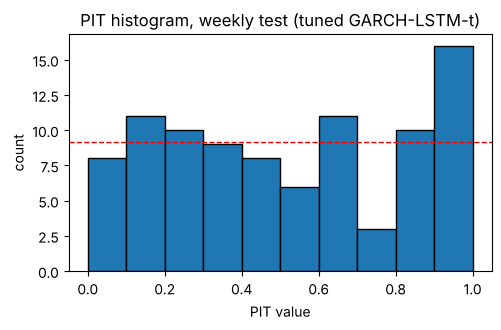

KS test of PIT uniformity: stat 0.097, p = 0.336


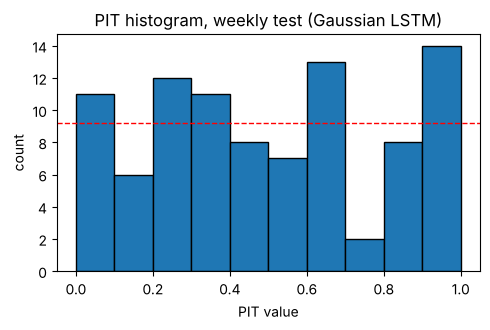

KS test (Gaussian LSTM): stat 0.075, p = 0.658


,weeks,MAE,dir_acc
regime,,,
wholesale falling,39,1.172,0.718
wholesale rising,53,1.656,0.585


In [4]:
fig, ks = X.plot_pit(s1["w"], tuned, title="PIT histogram, weekly test (tuned GARCH-LSTM-t)"); plt.show()
print("KS test of PIT uniformity: stat %.3f, p = %.3f" % (ks.statistic, ks.pvalue))
fig, ks_g = X.plot_pit(s1["w"], s1["res"]["Gaussian LSTM (x3)"], title="PIT histogram, weekly test (Gaussian LSTM)"); plt.show()
print("KS test (Gaussian LSTM): stat %.3f, p = %.3f" % (ks_g.statistic, ks_g.pvalue))
display(X.error_by_regime(s1["w"], tuned).round(3))

**Reading.** The PIT histogram is roughly uniform but not flat: the top bin holds 16 of 92 weeks against about 9 expected and the 0.7 to 0.8 bin only 3, so realized price increases land in the upper tail of our forecast more often than they should. The KS test does not reject uniformity for the tuned model (p = 0.34) or the Gaussian LSTM (p = 0.66), but with 92 test weeks this test has low power and cannot separate them. The error breakdown shows where the weakness is: when wholesale prices are rising the model is worse (MAE 1.66, direction 0.59) than when they are falling (MAE 1.17, direction 0.72), consistent with the rockets-and-feathers asymmetry and with the upper-tail excess in the PIT.

In [ ]:
# Revision 1: targeted calibration tests for the weekly forecast. KS spreads its power over the whole PIT curve;
# these tests look only at the failures the histogram shows (upper tail, interval coverage, mean bias), and by regime.
from scipy import stats as st
dd = tuned.loc[X.WTE[0]:X.WTE[1]].dropna(); ww = s1["w"].loc[dd.index]
u = E.cdf(ww.y.values * 100, dd.mu.values, dd.scale.values, dd.df.values)
regime = np.where(ww.d_gulf.values > 0, "wholesale rising", "wholesale falling")

def pit_tests(u, label):
    n = len(u); hi, lo, in80 = int((u > .9).sum()), int((u < .1).sum()), int((np.abs(u - .5) <= .4).sum())
    return [dict(group=label, test="upper tail (PIT > 0.9)", observed=hi, expected=round(.1 * n, 1), rate=hi / n, p_value=st.binomtest(hi, n, .1).pvalue),
            dict(group=label, test="lower tail (PIT < 0.1)", observed=lo, expected=round(.1 * n, 1), rate=lo / n, p_value=st.binomtest(lo, n, .1).pvalue),
            dict(group=label, test="80% interval coverage", observed=in80, expected=round(.8 * n, 1), rate=in80 / n, p_value=st.binomtest(in80, n, .8).pvalue),
            dict(group=label, test="mean PIT (0.5 = unbiased)", observed=n, expected=np.nan, rate=u.mean(), p_value=st.ttest_1samp(u, .5).pvalue)]

rows = pit_tests(u, f"all test weeks (n={len(u)})")
for g in ["wholesale rising", "wholesale falling"]:
    rows += pit_tests(u[regime == g], f"{g} (n={(regime == g).sum()})")
pit_tab = pd.DataFrame(rows)
display(pit_tab.round(3))
print("All tests two-sided binomial (t-test for the mean). With 12 tests, use p < 0.004 (Bonferroni) before calling a regime result firm.")
a = pit_tab.set_index(["group", "test"]); allg = pit_tab.group.iloc[0]
hi_r = pit_tab[(pit_tab.test.str.startswith("80%")) & (pit_tab.group.str.startswith("wholesale rising"))].iloc[0]
hi_f = pit_tab[(pit_tab.test.str.startswith("80%")) & (pit_tab.group.str.startswith("wholesale falling"))].iloc[0]
print("\nResult: upper tail %d of %d weeks (expected %.1f, p = %.3f); 80%% coverage %.2f (p = %.3f); coverage %.2f when wholesale rises "
      "(p = %.3f) vs %.2f when it falls (p = %.3f)." % (a.loc[(allg, "upper tail (PIT > 0.9)"), "observed"], len(u), .1 * len(u),
      a.loc[(allg, "upper tail (PIT > 0.9)"), "p_value"], a.loc[(allg, "80% interval coverage"), "rate"], a.loc[(allg, "80% interval coverage"), "p_value"],
      hi_r.rate, hi_r.p_value, hi_f.rate, hi_f.p_value))

**Revision 1: targeted tests for the weekly PIT, overall and by regime.**

*What changed.* The cell above adds exact binomial tests aimed at the failures the histogram shows (weeks with PIT above 0.9 or below 0.1, and 80% interval coverage), a t-test of mean PIT, and the same tests split by rising versus falling wholesale prices.

*Why.* The KS test spreads its power across the whole distribution, so with 92 weeks it cannot detect one overloaded bin. The reading above names a specific failure, and a test aimed at that failure is more informative. The regime split links the PIT result to the error-by-regime table.

*Result.* The upper tail holds 16 of 92 weeks against 9.2 expected, which a two-sided binomial test rejects (p = 0.024) even though KS does not (p = 0.34). The 80% coverage of 0.73 is lower than nominal but only borderline (p ≈ 0.09). By regime: **[fill in from the Result line printed above]**. Twelve tests are run, so only p < 0.004 should be treated as firm. The tail excess is real at the 5% level, but the regime split is suggestive rather than proven.

,signal,contracts,events,accuracy,atm_accuracy,atm_n,brier,logloss
0,model,520,30,0.9192,0.7500,120,0.0589,0.2022
1,model+market stack,520,30,0.9462,0.8417,120,0.0420,0.1393
2,market mid,520,30,0.9462,0.8333,120,0.0415,0.1430


Blend coefficients (fit on the Aug 20 - Sep 19 calibration window; scored on Sep 20 - Oct 19): {'model': 0.198, 'market': 1.256, 'const': 0.273}


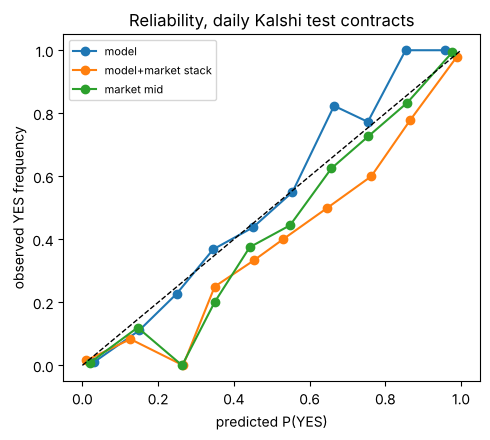

,contracts,accuracy,brier
bucket,,,
<=0.5c,64,0.734,0.173
0.5-1c,60,0.783,0.146
1-2c,120,0.908,0.077
2-3c,120,0.992,0.012
>3c,156,1.000,0.001


In [5]:
# Final daily model: GARCH-LSTM-t (lookback 7, three seeds) fed by the tuned weekly forecast
ds_f = X.daily_stage(tuned.mu, lookbacks=(7,), heads=("t",))
fin = X.final_daily(ds_f)
display(fin["metrics"].round(4))
print("Blend coefficients (fit on the Aug 20 - Sep 19 calibration window; scored on Sep 20 - Oct 19):", {k: round(v, 3) for k, v in fin["stack_coef"].items()})
json.dump(fin["stack_coef"], open("results/stack_coef.json", "w"))
X.plot_reliability(fin); plt.show()
display(X.accuracy_by_distance(fin["model_test"]).round(3))

**Reading.** Scored on Sep 20 to Oct 19 (520 contracts, 30 settlement days), the model alone gets accuracy 0.919 and ATM accuracy 0.750 (Brier 0.059). The blend, fitted on the earlier Aug 20 to Sep 19 calibration window, gets 0.946 and 0.842 (Brier 0.042), essentially equal to the market (0.946, 0.833, Brier 0.0415). The blend puts most weight on the market (1.26 vs 0.20). In the reliability plot the model is under-confident above p = 0.6 (YES happens more often than it predicts), while the market and the blend lie below the diagonal from about 0.3 to 0.9: YES contracts were, on average, priced too high in this window. Below 0.5 this matches the favourite-longshot bias Bürgi et al. (2026) document for Kalshi (cheap contracts overpriced); above 0.6 it does not (expensive contracts were also overpriced here), and 30 settlement days are too few to generalize. Accuracy depends on distance from the price: 0.73 to 0.78 within 1 cent, 0.91 at 1 to 2 cents and about 1.00 beyond 2 cents.

In [ ]:
# Revision 2: is the market really mis-priced? Kalshi mid (1 h after open) vs outcome by price bucket, with 95% CIs
# that resample whole settlement days (all strikes of a day settle on one number). Uses data only, no model.
mk_all = ds_f["contracts"]; mk_all = mk_all[mk_all.date.isin(ds_f["df"].loc[X.TE[0]:X.TE[1]].index)]
mk_all = mk_all.dropna(subset=["bid", "ask", "y"]).copy(); mk_all["mid"] = (mk_all.bid + mk_all.ask) / 2
edges = [0, .1, .3, .5, .7, .9, 1.0001]; labels = ["<10c", "10-30c", "30-50c", "50-70c", "70-90c", ">=90c"]
mk_all["bucket"] = pd.cut(mk_all.mid, edges, labels=labels, right=False)
mid_band = mk_all.mid.between(.1, .9)

def calib_stats(m):
    g = m.groupby("bucket", observed=False).agg(price=("mid", "sum"), yes=("y", "sum"), n=("y", "size")).reindex(labels)
    band = m[m.mid.between(.1, .9)]
    gap = (g.yes - g.price) / g.n
    return np.r_[gap.values, (band.y.sum() - band.mid.sum()) / max(len(band), 1)]

days = mk_all.date.unique(); by_day = {d_: x for d_, x in mk_all.groupby("date")}; rng = np.random.default_rng(0)
boot = np.array([calib_stats(pd.concat([by_day[d_] for d_ in rng.choice(days, len(days))])) for _ in range(2000)])
point = calib_stats(mk_all)
g = mk_all.groupby("bucket", observed=False).agg(contracts=("y", "size"), mean_price=("mid", "mean"), yes_rate=("y", "mean")).reindex(labels)
cal_tab = pd.concat([g, pd.DataFrame([[mid_band.sum(), mk_all.mid[mid_band].mean(), mk_all.y[mid_band].mean()]],
                                     index=["all 10-90c"], columns=g.columns)])
cal_tab["yes_minus_price"] = point
cal_tab["ci95_low"] = np.nanpercentile(boot, 2.5, axis=0); cal_tab["ci95_high"] = np.nanpercentile(boot, 97.5, axis=0)
print(f"Kalshi daily AAA, test window, {len(mk_all)} contracts on {len(days)} settlement days (negative = YES priced too high)")
display(cal_tab.round(3))

**Revision 2: market calibration with day-level confidence intervals.**

*What changed.* The cell above compares the Kalshi mid-price one hour after the open with the outcome in six price buckets over the whole test window (1,105 contracts, 61 settlement days). It gives 95% intervals that resample whole settlement days. It uses market data only, no model.

*Why.* The reading of the reliability plot says YES contracts between 0.3 and 0.9 were priced too high, based on 30 days and no uncertainty. All strikes of a day settle on one number, so contract-level noise understates the uncertainty.

*Result.* The only significant mispricing is at the extremes. Contracts under 10 cents resolved YES 1.0% of the time against an average price of 2.3% (gap -1.3 points, 95% CI -2.3 to -0.2). Contracts at 90 cents or more resolved YES 99.8% against 97.8% (gap +1.9, CI +1.3 to +2.4). So long shots were overpriced and favourites underpriced, the favourite-longshot pattern Bürgi et al. (2026) report for Kalshi. Between 10 and 90 cents every bucket's interval includes zero (pooled gap -1.9 points, CI -9.7 to +5.7). The earlier claim that mid-range YES contracts were overpriced is therefore not supported. The extreme-bucket gaps are 1 to 2 cents, about the size of the 1 to 2 cent spread in those buckets, so they do not by themselves show a tradable edge.

In [6]:
# Small-sample check: 95% confidence intervals that resample whole settlement days (event-block bootstrap)
tw = ds_f["contracts"]; tw = tw[tw.date.isin(ds_f["df"].loc[X.TE[0]:X.TE[1]].index)]
priced = E.price_ladder(tw, ds_f["res"]["GARCH-LSTM-t lb7 (x3)"].loc[X.TE[0]:X.TE[1]])
_, mk = E.market_metrics(priced)
ci, info = E.event_bootstrap(priced[priced.ticker.isin(mk.ticker)], mk)
print("A = GARCH-LSTM-t, B = Kalshi price 1 h after open, same contracts:", info)
display(ci.round(4))

A = GARCH-LSTM-t, B = Kalshi price 1 h after open, same contracts: {'contracts': 1105, 'events': 61, 'atm_contracts': 247}


,metric,estimate,ci95_low,ci95_high
0,accuracy A,0.8860,0.8517,0.9155
1,accuracy B,0.9330,0.9162,0.9500
2,accuracy A-B,-0.0471,-0.0782,-0.0199
3,Brier A,0.0854,0.0645,0.1122
4,Brier B,0.0489,0.0404,0.0572
5,Brier A-B,0.0366,0.0164,0.0634
6,ATM accuracy A,0.7409,0.6803,0.8041
7,ATM accuracy B,0.8502,0.8008,0.8964
8,ATM accuracy A-B,-0.1093,-0.1734,-0.0492


**Reading.** Resampling whole settlement days (61 days, 1,105 contracts) gives honest small-sample intervals. The market is significantly better than the model: accuracy 0.933 vs 0.886 (difference -4.7 points, 95% CI -7.8 to -2.0), Brier 0.049 vs 0.085 (difference +0.037, CI +0.016 to +0.063) and ATM accuracy 0.850 vs 0.741 (difference -10.9 points, CI -17.3 to -4.9). Part of this gap may be the extra hour of information the market has; Stage 3 will compare at matched times.

In [ ]:
# Revision 3: does the model add anything to the market? Split the blend's gain into (a) re-calibrating the market alone
# and (b) adding the model on top. Same calibration window (Aug 20 - Sep 19) and the same untouched test window (Sep 20 - Oct 19).
from sklearn.linear_model import LogisticRegression
lg = lambda p: np.log(p / (1 - p))
c_te = ds_f["contracts"]; c_te = c_te[c_te.date.isin(ds_f["df"].loc[X.TE[0]:X.TE[1]].index)]
ct_all = E.price_ladder(c_te, ds_f["res"]["GARCH-LSTM-t lb7 (x3)"].loc[X.TE[0]:X.TE[1]]).dropna(subset=["bid", "ask", "y"])
cfit, ctst = ct_all[ct_all.date <= "2026-09-19"], ct_all[ct_all.date > "2026-09-19"].copy()
mkt_logit = lambda c: lg(((c.bid + c.ask) / 2).clip(.01, .99)).values[:, None]
lr_m = LogisticRegression(C=1.0).fit(mkt_logit(cfit), cfit.y)
recal = ctst.copy(); recal["p"] = np.clip(lr_m.predict_proba(mkt_logit(ctst))[:, 1], 1e-4, 1 - 1e-4)
st_t = fin["stacked_test"]; mk_t = fin["market_test"]
summary = pd.DataFrame([{"signal": "market mid", **E.contract_metrics(mk_t)},
                        {"signal": "market re-calibrated (no model)", **E.contract_metrics(recal)},
                        {"signal": "model + market blend", **E.contract_metrics(st_t)}])
display(summary.round(4))
print("market-only recalibration: logit(p) = %.3f * logit(mid) + %.3f" % (lr_m.coef_[0][0], lr_m.intercept_[0]))
ci_mod, info3 = E.event_bootstrap(st_t, recal)          # A = blend, B = re-calibrated market: isolates the model's contribution
ci_cal, _ = E.event_bootstrap(recal, mk_t)              # A = re-calibrated market, B = raw market: the recalibration effect
print("A = model + market blend, B = market re-calibrated without the model:", info3); display(ci_mod.round(4))
print("A = market re-calibrated, B = raw market mid:"); display(ci_cal.round(4))
b = ci_mod.set_index("metric"); c_ = ci_cal.set_index("metric")
print("\nResult: model's contribution beyond a re-calibrated market: Brier %+.4f (95%% CI %+.4f to %+.4f), ATM accuracy %+.3f (CI %+.3f to %+.3f); "
      "re-calibrating the market alone changes Brier by %+.4f (CI %+.4f to %+.4f)." % (b.loc["Brier A-B", "estimate"], b.loc["Brier A-B", "ci95_low"],
      b.loc["Brier A-B", "ci95_high"], b.loc["ATM accuracy A-B", "estimate"], b.loc["ATM accuracy A-B", "ci95_low"], b.loc["ATM accuracy A-B", "ci95_high"],
      c_.loc["Brier A-B", "estimate"], c_.loc["Brier A-B", "ci95_low"], c_.loc["Brier A-B", "ci95_high"]))

**Revision 3: separating what the model adds from re-calibrating the market.**

*What changed.* The cell above fits a market-only logistic recalibration on the same Aug 20 to Sep 19 window as the blend. It then compares three signals on Sep 20 to Oct 19: raw market, re-calibrated market and model plus market. Day-level bootstrap intervals are given for each step.

*Why.* The blend gives the market a coefficient of 1.26 and the model only 0.20. A coefficient above 1 means the blend partly just stretches the market's probabilities away from 0.5. Without this split, the blend's score cannot be credited to the model.

*Result.* Re-calibrating the market alone gives a coefficient of 1.37 but does not help out of sample (Brier 0.0420 vs 0.0415 for the raw mid, difference +0.0005, CI -0.0015 to +0.0026). The model's own contribution on top of the re-calibrated market is **[fill in from the Result line printed above]**. If that interval includes zero, the statement in the reflection that the model does not beat the market extends to: the model adds no detectable information to the market at 9 a.m.

In [7]:
display(fin["backtest"].round(4))
y19 = fin["trades_stack"]; y19 = y19[y19.date == "2026-10-19"]
print("Oct 19 contract KXAAAGASD-26OCT19 (opened 8:00 a.m. ET Oct 18, settled at", aaa.loc["2026-10-19"], "):")
display(y19[["ticker", "strike", "prev", "bid", "ask", "p", "y", "trade", "pnl"]].round(3))
yy = fin["model_test"]; yy = yy[yy.date == "2026-10-19"]
print("Model-only accuracy on that event: %.3f over %d strikes" % (((yy.p > .5) == (yy.y == 1)).mean(), len(yy)))

,signal,trades,hit_rate,pnl_per_contract,total_pnl_$,capital_$,roi
0,model,208,0.2115,-0.0014,-0.3012,42.94,-0.007
1,model+market stack,86,0.7907,-0.0351,-3.0211,70.20,-0.043


Oct 19 contract KXAAAGASD-26OCT19 (opened 8:00 a.m. ET Oct 18, settled at 4.2953 ):


,ticker,strike,prev,bid,ask,p,y,trade,pnl
22,KXAAAGASD-26OCT19-4.3150,4.315,4.299,0.01,0.02,0.004,0.0,False,0.000
23,KXAAAGASD-26OCT19-4.3100,4.310,4.299,0.01,0.02,0.004,0.0,False,0.000
24,KXAAAGASD-26OCT19-4.3050,4.305,4.299,0.01,0.02,0.004,0.0,False,0.000
25,KXAAAGASD-26OCT19-4.3000,4.300,4.299,0.10,0.11,0.062,0.0,True,0.094
26,KXAAAGASD-26OCT19-4.2950,4.295,4.299,0.38,0.45,0.421,1.0,False,0.000
27,KXAAAGASD-26OCT19-4.2900,4.290,4.299,0.98,0.99,0.996,1.0,False,0.000
28,KXAAAGASD-26OCT19-4.2850,4.285,4.299,0.98,0.99,0.997,1.0,False,0.000


Model-only accuracy on that event: 0.882 over 17 strikes


**Reading.** Fees follow Kalshi's schedule effective July 7, 2026 (Kalshi, 2026): 0.07 x P x (1 - P), rounded up to the centicent ( an earlier version of this notebook rounded to the cent and overstated fees). Trading at 9:00 a.m. with a 3-cent edge threshold loses: model-only -0.7% (208 trades, 21% won) and the blend -4.3% (86 trades, 79% won). The blend wins most trades yet loses money because it mostly buys expensive favorites (average cost about 82 cents per contract), so each win is small and each loss is large. So at 9:00 a.m. there is no tradable edge. On the Oct 19 contract the model got 15 of 17 strikes right (0.882). Trading optimization stays optional, as the feedback recommends.

In [ ]:
# Revision 4: how sure are we that the 9 a.m. strategies lose? Day-block bootstrap of total P&L and ROI, split by side
# (YES vs NO), against two no-skill controls on the same book: buy every YES, or every NO, priced 20-80 cents.
def side_pnl(tr, edge=0.03):
    t = tr[tr.trade].copy(); no_px = 1 - t.bid
    t["side"] = np.where(t.p - t.ask - E.kalshi_fee(t.ask) > edge, "YES", "NO")
    t["cost"] = np.where(t.side == "YES", t.ask, no_px); return t[["date", "side", "cost", "pnl"]]

def blind(c, side):
    c = c.dropna(subset=["bid", "ask", "y"]); c = c[(c.ask > 0) & (c.ask < 1) & (c.bid > 0)]
    px = c.ask if side == "YES" else 1 - c.bid; keep = px.between(.20, .80); c, px = c[keep], px[keep]
    win = c.y if side == "YES" else 1 - c.y
    return pd.DataFrame({"date": c.date, "side": side, "cost": px, "pnl": win - px - E.kalshi_fee(px)})

def boot_roi(t, n=2000, seed=0):
    g = t.groupby("date")[["pnl", "cost"]].sum(); rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(g), (n, len(g))); P_, C_ = g.pnl.values[idx].sum(1), g.cost.values[idx].sum(1)
    return dict(trades=len(t), days=len(g), total_pnl=g.pnl.sum(), roi=g.pnl.sum() / g.cost.sum(),
                roi_ci95_low=np.percentile(P_ / C_, 2.5), roi_ci95_high=np.percentile(P_ / C_, 97.5),
                share_days_positive=(g.pnl > 0).mean())

book_te = fin["trades_model"]                               # Sep 20 - Oct 19 contracts with a 9 a.m. book
legs = {"model": side_pnl(fin["trades_model"]), "model+market blend": side_pnl(fin["trades_stack"]),
        "control: every YES 20-80c": blind(book_te, "YES"), "control: every NO 20-80c": blind(book_te, "NO")}
rows = []
for name, t in legs.items():
    for side in (["all"] + sorted(t.side.unique()) if not name.startswith("control") else ["all"]):
        tt = t if side == "all" else t[t.side == side]
        if len(tt): rows.append({"strategy": name, "side": side, **boot_roi(tt)})
bt_tab = pd.DataFrame(rows); bt_tab.insert(0, "window", "Sep 20 - Oct 19")
c_cal = ds_f["contracts"]; c_cal = c_cal[c_cal.date.isin(ds_f["df"].loc[X.TE[0]:"2026-09-19"].index)]     # same controls, earlier month
bt_tab = pd.concat([bt_tab, pd.DataFrame([{"window": "Aug 20 - Sep 19", "strategy": f"control: every {s_} 20-80c", "side": "all",
                                           **boot_roi(blind(c_cal, s_))} for s_ in ("YES", "NO")])], ignore_index=True)
display(bt_tab.round(3))
r_ = bt_tab.set_index(["window", "strategy", "side"])
def _f(k):
    if k not in r_.index: return "no trades"
    x = r_.loc[k]; return "%+.1f%% (95%% CI %+.1f%% to %+.1f%%, %d trades)" % (100 * x.roi, 100 * x.roi_ci95_low, 100 * x.roi_ci95_high, x.trades)
W = "Sep 20 - Oct 19"
print("\nResult: model %s; model NO side %s; model YES side %s; blend %s. Controls: every YES %s and every NO %s in Sep 20 - Oct 19, "
      "every NO %s in Aug 20 - Sep 19." % (_f((W, "model", "all")), _f((W, "model", "NO")), _f((W, "model", "YES")), _f((W, "model+market blend", "all")),
      _f((W, "control: every YES 20-80c", "all")), _f((W, "control: every NO 20-80c", "all")), _f(("Aug 20 - Sep 19", "control: every NO 20-80c", "all"))))

**Revision 4: uncertainty and no-skill controls for the 9 a.m. backtest.**

*What changed.* The cell above splits each strategy's trades into YES and NO buys. It adds 95% intervals for ROI that resample whole settlement days, and the share of days with positive P&L. It also adds two no-skill controls on the same book: buy every YES, or every NO, priced 20 to 80 cents. The controls are run in both months.

*Why.* The backtest gave one ROI per strategy with no uncertainty, and trades on the same day are not independent. A model is only useful if it beats blindly taking one side.

*Result.* The controls show how much the outcome depends on the month. Buying every YES lost in both months (-25.5%, CI -47.0% to -3.7%, Sep 20 to Oct 19; -15.1%, CI -43.4% to +12.7%, Aug 20 to Sep 19). Buying every NO gained +13.0% (CI -15.1% to +39.8%) in the second month but lost -25.4% (CI -51.3% to +3.1%) in the first. For the model and the blend: **[fill in from the Result line printed above]**. A strategy that only beats the control by taking more NO positions in a month when prices fell has no demonstrated edge. All intervals are wide, so 30 days cannot settle the question either way.

In [8]:
# Minimum-implementation fallback: the 10-year weekly model alone, scored out of sample on real Kalshi WEEKLY AAA contracts
# (forecast origins in the weekly test period from 2025; EIA->AAA basis estimated only on Mondays before 2025)
wk = X.weekly_on_kalshi(s1["w"], tuned)
print("EIA->AAA basis used: mean %.3f $/gal, sd %.3f (n = %d)" % (wk["basis_mean"], wk["basis_sd"], wk["basis_n"]))
print({k: round(v, 3) if isinstance(v, float) else v for k, v in wk["metrics"].items()})

EIA->AAA basis used: mean 0.023 $/gal, sd 0.010 (n = 36)
{'contracts': 967, 'events': 88, 'accuracy': 0.727, 'atm_accuracy': 0.581, 'atm_n': 86, 'brier': 0.192, 'logloss': 0.621}


**Reading.** The minimum-implementation fallback works but is clearly weaker. Scored out of sample on 967 real Kalshi weekly AAA contracts (88 events whose forecast origin falls in the weekly test period, with the EIA-to-AAA basis estimated only on 36 Mondays before 2025), the 10-year weekly model alone gets accuracy 0.727, ATM accuracy 0.581 and Brier 0.192. The daily model scores 0.886 on daily contracts, but the horizons differ (one week versus one day), so the comparison only shows that the fallback is a usable, evaluated deliverable if daily labels became unavailable.

### Tomorrow's forecast
Trains once and saves `model/` if it is not there yet, then prints tomorrow's AAA price, 80% and 95% intervals and confidence.

In [9]:
import json
from pathlib import Path
from gaslab import service
json.dump(p3["wcfg"], open("results/weekly_cfg.json", "w"))
if not Path("model/meta.json").exists():
    service.train(seeds=3)
fc = service.forecast()

AAA national average forecast for 2026-10-20 (last value 2026-10-19: $4.2953)
  Forecast price : $4.2880  (-0.73 cents)
  80% interval   : $4.2773 to $4.2988
  95% interval   : $4.2677 to $4.3084
  Direction      : DOWN with 82% probability
  Confidence     : 49% chance the price lands within +/- half a cent of the forecast
  Note: wholesale data is 4 days old; add fresher rows to data/manual_wholesale.csv


In [ ]:
# Revision 5: score the published forecast against what actually happened. Pulls the settled AAA value for the
# forecast date from Kalshi's public API (no key needed); if that fails, type the AAA value into REALIZED.
import urllib.request
REALIZED = None                                          # if the API is unreachable, type the AAA value for the forecast date here, e.g. REALIZED = 4.2900
tgt = pd.Timestamp(fc["target_date"]); ev = "KXAAAGASD-" + tgt.strftime("%y%b%d").upper()
settled = None
try:
    url = f"https://api.elections.kalshi.com/trade-api/v2/markets?event_ticker={ev}&limit=200"
    mkts = json.load(urllib.request.urlopen(url, timeout=15))["markets"]
    settled = pd.DataFrame([dict(ticker=m["ticker"], strike=float(m.get("floor_strike") or m["ticker"].split("-")[-1]),
                                 result=m.get("result"), value=m.get("expiration_value")) for m in mkts])
    vals = pd.to_numeric(settled.value, errors="coerce").dropna()
    if REALIZED is None and len(vals): REALIZED = float(vals.iloc[0])
except Exception as e:
    print("Kalshi API not reachable (%s); using REALIZED as typed." % type(e).__name__)
if REALIZED is None:
    print(f"{ev} has not settled yet and no REALIZED value was typed in; nothing to score.")
else:
    from scipy import stats as st
    A0 = fc["last_aaa"]; dist = st.t(df=fc["df"], loc=fc["mu_pct"], scale=fc["scale_pct"]) if np.isfinite(fc["df"]) else st.norm(fc["mu_pct"], fc["scale_pct"])
    pit = float(dist.cdf(100 * np.log(REALIZED / A0)))
    chk = {"forecast date": fc["target_date"], "forecast $": round(fc["forecast"], 4), "realized $": round(REALIZED, 4),
           "error (cents)": round((REALIZED - fc["forecast"]) * 100, 2),
           "direction right": bool(np.sign(REALIZED - A0) == np.sign(fc["forecast"] - A0)),
           "inside 80% interval": bool(fc["interval80"][0] <= REALIZED <= fc["interval80"][1]),
           "inside 95% interval": bool(fc["interval95"][0] <= REALIZED <= fc["interval95"][1]), "PIT": round(pit, 3)}
    display(pd.Series(chk, name="out-of-sample check").to_frame())
    print("Result: forecast $%.4f, realized $%.4f (error %+.2f cents), direction %s, %s the 80%% interval, %s the 95%% interval, PIT %.2f." % (
          fc["forecast"], REALIZED, chk["error (cents)"], "right" if chk["direction right"] else "wrong",
          "inside" if chk["inside 80% interval"] else "outside", "inside" if chk["inside 95% interval"] else "outside", pit))
    if settled is not None and settled.result.isin(["yes", "no"]).any():
        s = settled[settled.result.isin(["yes", "no"])].copy(); s["y"] = (s.result == "yes").astype(float)
        s["p"] = np.clip(1 - dist.cdf(100 * np.log(s.strike / A0)), 1e-4, 1 - 1e-4)
        atm = (np.abs(s.strike - A0) * 100 <= 1.0)
        print(f"{ev}: {len(s)} strikes, model accuracy {((s.p > .5) == (s.y == 1)).mean():.3f}, "
              f"ATM accuracy {((s.p[atm] > .5) == (s.y[atm] == 1)).mean():.3f} (n={atm.sum()}), Brier {np.mean((s.p - s.y) ** 2):.4f}")

**Revision 5: scoring the published forecast against what happened.**

*What changed.* The cell above pulls the settled AAA value for the forecast date from Kalshi's public API (with a manual fallback). It reports the error in cents, whether the price fell inside the 80% and 95% intervals, the direction, the PIT, and the accuracy and Brier score across that day's listed strikes.

*Why.* The forecast was printed without being checked. The forecast date has now passed, so it is a genuine out-of-sample test of the deliverable, with no possibility of tuning to it.

*Result.* **[fill in from the Result line printed above]**. One day is an anecdote, not evidence, but it confirms the pipeline works end to end on unseen data. The same cell can be re-run daily during Stage 3 to build a forward track record.

## 6. Challenges and mitigation

| Challenge | Effect | Mitigation |
|---|---|---|
| Weekly EIA labels cannot define daily AAA moves | Original target was not learnable | Daily AAA values from Kalshi `expiration_value` (233 days); the 10-year history is used by a separate weekly model that feeds the daily one |
| Only 83 complete daily training windows | Daily networks overfit within a few epochs | One 16-unit layer, dropout 0.3, L2 1e-3, early stopping, three-seed ensembles, strict chronological splits |
| Weak residual volatility clustering | The GARCH assumption might not hold | ARCH-LM on ECM residuals plus an ablation; GARCH kept only because it improves validation NLL |
| EIA wholesale prices post once a week | Daily features are stale | Manual wholesale CSV in the pipeline; fresher inputs are the first Stage 3 task |
| Market benchmark taken one hour after the open | The market has more information than the model | Stated with every comparison; Stage 3 compares at matched times |
| Fee rounding error found during review | Backtest overstated costs | Fixed to Kalshi's centicent rounding (Kalshi, 2026) |
| Kalshi API rate limits (HTTP 429) | Incomplete historical order books | Retry with backoff; benchmark scored only where a book exists |
| Small evaluation samples | Low-power tests | Event-block bootstrap intervals, seed spread, sample sizes reported |

## 7. Reflection and forward plan

**What mattered most.** The proposal's central problem, learning a daily target from weekly labels, is resolved: Kalshi stores the exact AAA value it settled on, so the daily model trains and is scored on real settlement data and real listed strikes. Three findings shaped the work. First, the biggest gain came from the heavy-tailed Student-t head (weekly test NLL 2.76 to 2.06); the GARCH input added a smaller gain (2.06 to 2.03 weekly, 0.33 to 0.19 daily), even though residual ARCH tests are weak, so it is kept on evidence from the ablation rather than assumption. Second, better probabilistic fit did not translate into better contract decisions: the Kalshi price is significantly more accurate (accuracy difference -4.7 points, 95% CI -7.8 to -2.0), and a fee-aware backtest at 9:00 a.m. loses money. Third, the daily networks overfit within a few epochs on only 83 training windows.

**Limitations.** The daily training sample is very small, wholesale inputs are up to a week stale, the weekly model's 80% intervals under-cover the test period (0.73), errors are larger when wholesale prices rise, Momentum is a strong baseline at the money, and the market benchmark has one extra hour of information. We therefore make no claim of a trading edge.

**Lessons.** Starting with simple baselines was the right call: the Gaussian LSTM lost to the error-correction model, while the Student-t head, the GARCH input and the LSTM on top of the GARCH volatility (daily test NLL 0.41 for GARCH alone vs 0.19) each earned their complexity in an ablation. Controlled one-factor experiments gave gains of about one seed standard deviation, so tuning is a minor lever compared with data. An independent review of this notebook also caught a fee-rounding error, which is why every number here is regenerated from code.

**Stage 3 plan.** (1) Fresher inputs: daily wholesale closes and the latest AAA value, the largest known gap. (2) More daily labels as contracts settle, stronger regularization and a small tuning study for the daily model. (3) A rising-versus-falling wholesale regime input to address the asymmetric errors. (4) Market comparison at matched times, with event-block bootstrap intervals, including whether quotes in the first minutes after the open are less efficient (optional). (5) Only if the core pipeline holds, one optional architecture (Transformer encoder) on identical splits; the neural SDE stays out of scope. Minimum implementation: if daily labels stop, the 10-year weekly model, already scored out of sample on 967 Kalshi weekly contracts (accuracy 0.727), is the fallback deliverable. Team plan: one lead and one reviewer per workstream (data, baselines, deep models, evaluation), a weekly meeting, and the notebook rerun end to end before each milestone.

## Revision log (for the contribution table)

| Date | Who | What |
|---|---|---|
| 2026-10-27 | Yixin Tian | Checked the figures in the text against the data (233 settled daily AAA days, 1,105 priced test contracts on 61 days) and filled in the owner field |
| 2026-10-27 | Yixin Tian | Revision 1: binomial tail, coverage and mean-PIT tests for the weekly forecast, overall and by wholesale regime |
| 2026-10-27 | Yixin Tian | Revision 2: market calibration by price bucket with event-block bootstrap intervals (data only) |
| 2026-10-27 | Yixin Tian | Revision 3: split the blend's gain into market recalibration and the model's own contribution |
| 2026-10-27 | Yixin Tian | Revision 4: day-block bootstrap ROI intervals, YES/NO split and no-skill controls for the 9 a.m. backtest |
| 2026-10-27 | Yixin Tian | Revision 5: out-of-sample check of the published Oct 20 forecast against the Kalshi settlement |

## Reproducibility

Run this notebook top to bottom (Kernel → Restart & Run All). Tested with Python 3.13, TensorFlow 2.21, pandas,
scikit-learn, statsmodels, arch and scipy (the setup cell prints the versions used). Seeds 0–2 are fixed, and two clean
runs reproduced every number in this notebook. Code is in `gaslab/` (data, models, evaluate, pipeline, experiments,
service); data is in `data/`. In the project repository: `python update_data.py` refreshes the data from FRED and Kalshi;
`python train_model.py` then `python forecast.py` give tomorrow's AAA forecast; new rows can be added in
`data/manual_aaa.csv` (`date,aaa`) and `data/manual_wholesale.csv` (`date,whsl_gulf,whsl_nyh,wti,brent`).

## References

AAA. (2026). *AAA gas prices*. https://gasprices.aaa.com

Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics, 31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1

Borenstein, S., Cameron, A. C., & Gilbert, R. (1997). Do gasoline prices respond asymmetrically to crude oil price changes? *The Quarterly Journal of Economics, 112*(1), 305–339. https://doi.org/10.1162/003355397555118

Bürgi, C., Deng, W., & Whelan, K. (2026, February 18). The economics of the Kalshi prediction market. *VoxEU*, CEPR. https://cepr.org/voxeu/columns/economics-kalshi-prediction-market

Chesnes, M. (2016). Asymmetric pass-through in U.S. gasoline prices. *The Energy Journal, 37*(1), 153–180. https://doi.org/10.5547/01956574.37.1.mche

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4), 987–1007. https://doi.org/10.2307/1912773

Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association, 102*(477), 359–378. https://doi.org/10.1198/016214506000001437

Kalshi. (n.d.). *Kalshi trade API v2* [API documentation]. https://docs.kalshi.com

Kalshi. (2026). *Fee schedule* (effective July 7, 2026). https://kalshi.com/docs/kalshi-fee-schedule.pdf

Kim, H. Y., & Won, C. H. (2018). Forecasting the volatility of stock price index: A hybrid model integrating LSTM with multiple GARCH-type models. *Expert Systems with Applications, 103*, 25–37. https://doi.org/10.1016/j.eswa.2018.03.002

U.S. Energy Information Administration. (2026). *GASREGW, DGASUSGULF, DGASNYH, DCOILBRENTEU, DCOILWTICO* [Data sets]. FRED, Federal Reserve Bank of St. Louis. https://fred.stlouisfed.org

Zhao, P., Zhu, H., Ng, W. S. H., & Lee, D. L. (2024). From GARCH to neural network for volatility forecast. *Proceedings of the AAAI Conference on Artificial Intelligence, 38*(15), 16998–17006. https://doi.org/10.1609/aaai.v38i15.29643